# Практика 2. Машинное зрение с нуля: учим сеть «видеть»

---

### Цель работы
Собрать и обучить **свёрточную нейронную сеть (CNN)** с нуля и своими глазами увидеть разницу между моделью со случайными весами и обученной моделью.

### Что вы сможете после этой практики
1. Объяснить, что изображение для компьютера — это просто матрица чисел.
2. Собрать CNN из слоёв `Conv2d → BatchNorm → ReLU → MaxPool` и понять, зачем нужен каждый.
3. Обучить модель, снять метрики (accuracy, loss, матрица ошибок) и **защитить результат цифрами**.
4. Найти классы, которые сеть путает, и объяснить почему.

### Как устроен ноутбук
| Этап | Что происходит |
|---|---|
| 1 | Загрузка данных, смотрим, как выглядит датасет |
| 2 | **ДО обучения** — сеть со случайными весами угадывает (~10%) |
| 3 | Обучение — пишем свой цикл обучения на PyTorch |
| 4 | **ПОСЛЕ обучения** — accuracy, кривые обучения, матрица ошибок, ошибки модели |
| 5 | Выводы + домашнее задание |


In [ ]:
!pip install -q torch torchvision scikit-learn matplotlib

In [ ]:
# 1. Импорт библиотек
import time
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", DEVICE)
if DEVICE == "cuda":
    print("Видеокарта:", torch.cuda.get_device_name(0))

# фиксируем случайность — чтобы результаты можно было воспроизвести
random.seed(42); np.random.seed(42); torch.manual_seed(42)

Устройство: cuda
Видеокарта: Tesla T4


## 🔧 БЛОК НАСТРОЕК — это вы будете менять в домашнем задании

`DATASET` — какой датасет берём:
* `"fashion"` — Fashion-MNIST, 10 классов одежды, ч/б 28×28 (быстро, ~26 МБ)
* `"digits"` — MNIST, рукописные цифры 0–9 (ещё быстрее)
* `"cifar"` — CIFAR-10, цветные фото 32×32 (самолёт, кошка, корабль…) — тяжелее, но интереснее

In [ ]:
# ==========================================
# НАСТРОЙКИ ЭКСПЕРИМЕНТА
# ==========================================
DATASET      = "fashion"   # "fashion" | "digits" | "cifar"
TRAIN_SIZE   = 10000       # сколько примеров берём для обучения (из 60000)
TEST_SIZE    = 2000        # сколько примеров для проверки (из 10000)
BATCH_SIZE   = 128
EPOCHS       = 8
LR           = 1e-3         # learning rate — скорость обучения
CHANNELS     = 32           # «ширина» сети: сколько фильтров в первом свёрточном слое

DATA_DIR = "./data"
print(f"Датасет: {DATASET} | train: {TRAIN_SIZE} | epochs: {EPOCHS}")

Датасет: fashion | train: 10000 | epochs: 8


## Этап 1. Данные: как изображение выглядит «изнутри»

In [ ]:
# ==========================================
# ЗАГРУЗКА ДАННЫХ
# ==========================================
SETTINGS = {
    # Fashion-MNIST и MNIST: 1 канал (ч/б), картинка 28x28
    "fashion": (datasets.FashionMNIST, (0.5,),        (0.5,)),
    "digits":  (datasets.MNIST,        (0.5,),        (0.5,)),
    # CIFAR-10: 3 канала (RGB), картинка 32x32
    "cifar":   (datasets.CIFAR10,      (0.5,0.5,0.5), (0.5,0.5,0.5)),
}

DatasetClass, mean, std = SETTINGS[DATASET]
transform = transforms.Compose([
    transforms.ToTensor(),                      # картинка -> тензор [C, H, W], значения 0..1
    transforms.Normalize(mean, std),            # нормализация: (x - mean) / std  -> около 0
])

train_full = DatasetClass(DATA_DIR, train=True,  download=True, transform=transform)
test_full  = DatasetClass(DATA_DIR, train=False, download=True, transform=transform)

train_ds = Subset(train_full, range(TRAIN_SIZE))
test_ds  = Subset(test_full,  range(TEST_SIZE))

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False)

CLASS_NAMES = train_full.classes
NUM_CLASSES = len(CLASS_NAMES)
IN_CHANNELS = 1 if DATASET != "cifar" else 3
IMG_SIZE    = train_ds[0][0].shape[-1]

print(f"Классов: {NUM_CLASSES} | каналов: {IN_CHANNELS} | размер: {IMG_SIZE}x{IMG_SIZE}")
print(f"Обучение: {len(train_ds)} картинок | Проверка: {len(test_ds)} картинок")
print("Названия классов:", CLASS_NAMES)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 218kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.6MB/s]


Классов: 10 | каналов: 1 | размер: 28x28
Обучение: 10000 картинок | Проверка: 2000 картинок
Названия классов: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [ ]:
# Как выглядит один пример
x, y = train_ds[0]
print("Форма тензора (C, H, W):", tuple(x.shape))
print("Метка (номер класса):", y, "->", CLASS_NAMES[y])
print("Минимум / максимум пикселя:", round(float(x.min()), 3), "/", round(float(x.max()), 3))
print()
print("Фрагмент картинки 8x8 пикселей — именно такие ЧИСЛА видит нейросеть:")
print(np.round(x[0, 10:18, 10:18].numpy(), 2))

Форма тензора (C, H, W): (1, 28, 28)
Метка (номер класса): 9 -> Ankle boot
Минимум / максимум пикселя: -1.0 / 1.0

Фрагмент картинки 8x8 пикселей — именно такие ЧИСЛА видит нейросеть:
[[-1.   -1.   -1.    0.51  0.79  0.71  0.67  0.55]
 [-0.98 -1.   -0.91  0.72  0.73  0.66  0.71  0.51]
 [-0.95 -1.   -0.22  0.91  0.74  0.73  0.71  0.59]
 [-1.   -1.   -0.57  0.85  0.79  0.8   0.79  0.88]
 [-1.   -1.    0.86  0.77  0.7   0.75  0.74  0.72]
 [ 0.14  0.6   0.79  0.62  0.67  0.73  0.71  0.63]
 [ 0.73  0.74  0.7   0.77  0.57  0.61  0.65  0.8 ]
 [ 0.63  0.64  0.57  0.25  0.92  0.51  0.62  0.75]]


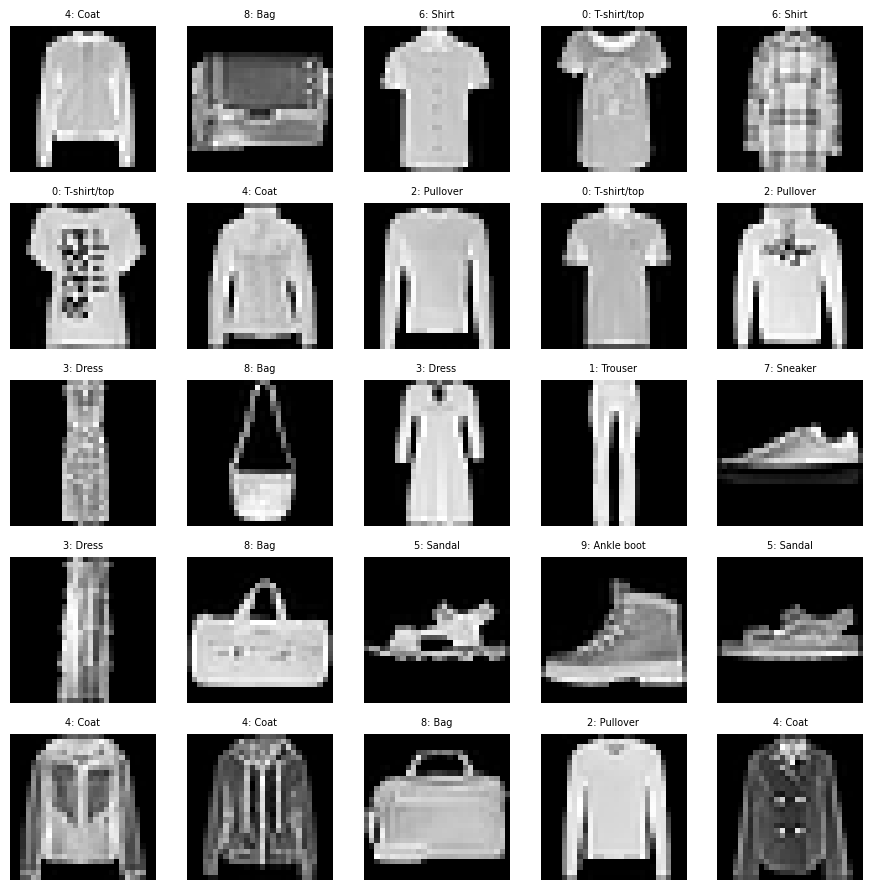

In [ ]:
# Смотрим 25 случайных картинок с подписями
fig, axes = plt.subplots(5, 5, figsize=(9, 9))
idxs = random.sample(range(len(train_ds)), 25)
for ax, i in zip(axes.ravel(), idxs):
    x, y = train_ds[i]
    img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
    if img.ndim == 3:
        img = img * 0.5 + 0.5          # возвращаем из нормализации в 0..1
    ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
    ax.set_title(f"{y}: {CLASS_NAMES[y]}", fontsize=7)
    ax.axis("off")
plt.tight_layout(); plt.show()

## Модель: маленькая свёрточная сеть

```
Вход [1, 28, 28]
  └─ Conv2d(32)  → ищет простые признаки: края, углы, пятна
  └─ BatchNorm   → стабилизирует обучение
  └─ ReLU        → нелинейность (без неё сеть = один линейный слой)
  └─ MaxPool 2x2 → уменьшает картинку в 2 раза, оставляет «самое важное»
  └─ Conv2d(64)  → из простых признаков собирает сложные: рукав, подошва, карман
  └─ MaxPool 2x2
  └─ Flatten → Linear(128) → Dropout → Linear(10)  = «головка» классификатора
```

**Свёртка** — это маленькое «окошко» (ядро 3×3), которое скользит по картинке и в каждой точке считает взвешенную сумму. Веса окна сеть **учит сама**.

In [ ]:
# ==========================================
# АРХИТЕКТУРА CNN
# ==========================================
class TinyCNN(nn.Module):
    def __init__(self, in_channels=1, num_classes=10, channels=32, img_size=28):
        super().__init__()
        s = img_size // 4                      # размер карты признаков после двух пулингов
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, channels,     kernel_size=3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(channels, channels * 2,    kernel_size=3, padding=1),
            nn.BatchNorm2d(channels * 2),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels * 2 * s * s, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))

model = TinyCNN(IN_CHANNELS, NUM_CLASSES, CHANNELS, IMG_SIZE).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nВсего параметров: {n_params:,}  (~{n_params/1e6:.2f} МБ в float32)")

TinyCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Всего параметров: 421,834  (~0.42 МБ в float32)


## Этап 2. ДО обучения: что умеет сеть со случайными весами?

Запускаем **ещё не обученную** модель на тестовых данных. Угадывать 1 из 10 классов наугад = 10%. Посмотрим, что покажет сеть.

In [ ]:
# ==========================================
# ФУНКЦИИ ОБУЧЕНИЯ И ПРОВЕРКИ
# ==========================================
def evaluate(model, dataloader):
    # Возвращает accuracy, список настоящих и предсказанных меток.
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x).argmax(dim=1)
            y_true += y.tolist(); y_pred += pred.tolist()
    return accuracy_score(y_true, y_pred), y_true, y_pred

def predict_one(model, x):
    # Предсказание + уверенность для одной картинки.
    model.eval()
    with torch.no_grad():
        logits = model(x.unsqueeze(0).to(DEVICE))[0]
        probs = logits.softmax(dim=0)
        cls = int(probs.argmax())
    return cls, float(probs[cls]), probs.cpu().numpy()

def show_samples(model, dataset, n=12, seed=7, title=""):
    # Сетка картинок с предсказаниями: зелёная рамка — верно, красная — ошибка.
    model.eval()
    fig, axes = plt.subplots(2, n // 2, figsize=(n * 1.15, 3.0))
    for ax, i in zip(axes.ravel(), random.Random(seed).sample(range(len(dataset)), n)):
        x, y = dataset[i]
        cls, conf, _ = predict_one(model, x)
        img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
        if img.ndim == 3:
            img = img * 0.5 + 0.5
        ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
        ax.set_title(f"→ {CLASS_NAMES[cls][:12]}\n{conf:.0%}", fontsize=7,
                     color="green" if cls == y else "red")
        ax.set_xlabel(f"truth: {CLASS_NAMES[y][:12]}", fontsize=6)
        ax.axis("off")
        for s in ax.spines.values():
            s.set_edgecolor("green" if cls == y else "red"); s.set_linewidth(2)
    if title: fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

# --- ЭТАП 2: проверка ДО обучения ---
acc_before, _, _ = evaluate(model, test_dl)
print("=" * 60)
print("ЭТАП 2: МОДЕЛЬ ДО ОБУЧЕНИЯ (веса случайные)")
print("=" * 60)
print(f"Accuracy: {acc_before*100:.2f}%   (случайное угадывание = {100/NUM_CLASSES:.1f}%)")

ЭТАП 2: МОДЕЛЬ ДО ОБУЧЕНИЯ (веса случайные)
Accuracy: 12.90%   (случайное угадывание = 10.0%)


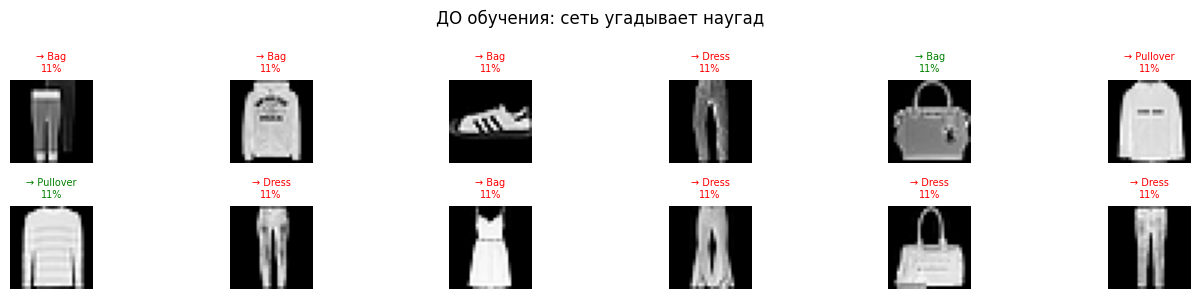

In [ ]:
show_samples(model, test_ds, n=12, seed=7, title="ДО обучения: сеть угадывает наугад")

## Этап 3. Обучение: цикл из четырёх строк

Каждый шаг (batch) делает одно и то же:

```python
optimizer.zero_grad()      # 1. обнуляем старые градиенты
loss = criterion(out, y)   # 2. считаем, насколько ошиблись
loss.backward()            # 3. считаем градиенты (кто виноват)
optimizer.step()           # 4. чуть-чуть меняем веса против ошибки
```

Это **и есть** машинное обучение. Всё остальное — обвязка.

In [ ]:
# ==========================================
# ОБУЧЕНИЕ
# ==========================================
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

history = {"train_loss": [], "train_acc": [], "test_acc": []}
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss, n_samples, correct = 0.0, 0, 0
    for x, y in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        n_samples  += x.size(0)
        correct    += (out.argmax(1) == y).sum().item()

    train_loss = total_loss / n_samples
    train_acc  = correct / n_samples
    test_acc, _, _ = evaluate(model, test_dl)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)
    print(f"Epoch {epoch:>2}/{EPOCHS} | loss {train_loss:.4f} | "
          f"train acc {train_acc*100:5.2f}% | test acc {test_acc*100:5.2f}%")

train_time = time.time() - t0
print(f"\nОбучение заняло {train_time:.1f} секунд на {DEVICE}")

Epoch  1/8 | loss 0.7201 | train acc 73.70% | test acc 84.30%
Epoch  2/8 | loss 0.4458 | train acc 84.25% | test acc 85.25%
Epoch  3/8 | loss 0.3806 | train acc 86.52% | test acc 88.30%
Epoch  4/8 | loss 0.3252 | train acc 88.29% | test acc 87.80%
Epoch  5/8 | loss 0.2994 | train acc 89.37% | test acc 89.35%
Epoch  6/8 | loss 0.2760 | train acc 89.85% | test acc 89.10%
Epoch  7/8 | loss 0.2400 | train acc 91.33% | test acc 89.85%
Epoch  8/8 | loss 0.2271 | train acc 91.59% | test acc 88.45%

Обучение заняло 23.3 секунд на cuda


## Этап 4. ПОСЛЕ обучения: метрики и разбор ошибок

In [ ]:
acc_after, y_true, y_pred = evaluate(model, test_dl)
print("=" * 60)
print("ЭТАП 4: МОДЕЛЬ ПОСЛЕ ОБУЧЕНИЯ")
print("=" * 60)
print(f"Accuracy ДО обучения:  {acc_before*100:6.2f}%")
print(f"Accuracy ПОСЛЕ:        {acc_after*100:6.2f}%")
print(f"Прирост:               {(acc_after-acc_before)*100:+6.2f} п.п. за {train_time:.0f} c")

ЭТАП 4: МОДЕЛЬ ПОСЛЕ ОБУЧЕНИЯ
Accuracy ДО обучения:   12.90%
Accuracy ПОСЛЕ:         88.45%
Прирост:               +75.55 п.п. за 23 c


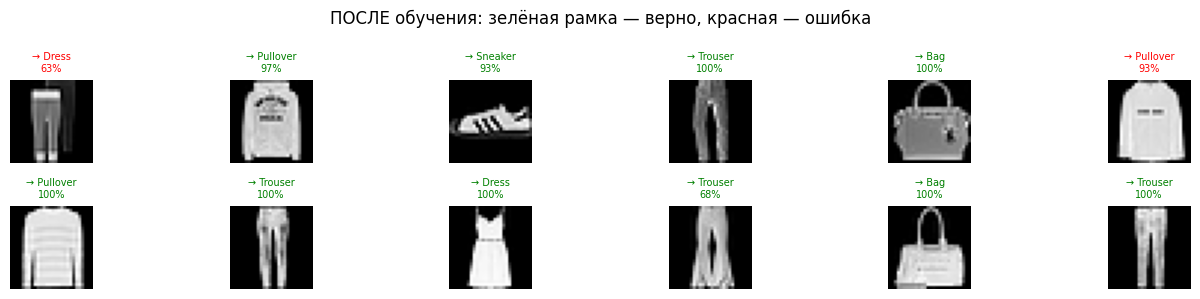

In [ ]:
show_samples(model, test_ds, n=12, seed=7, title="ПОСЛЕ обучения: зелёная рамка — верно, красная — ошибка")

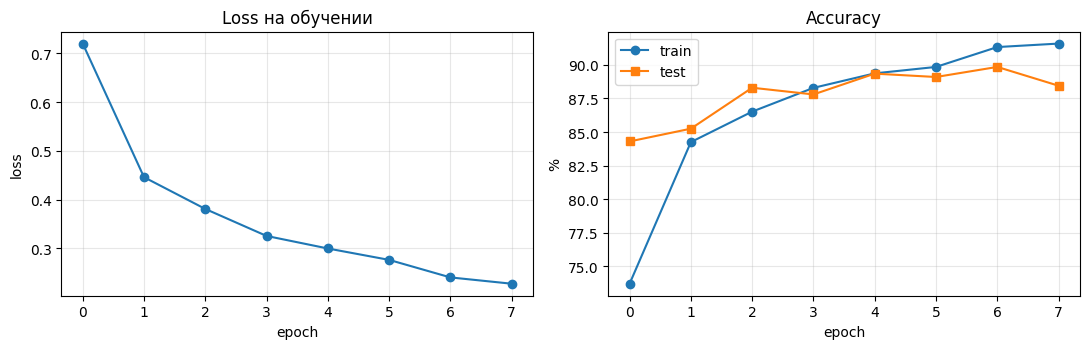

Как читать график:
 • loss падает, обе accuracy растут  → обучение идёт нормально
 • train растёт, test остановился    → переобучение (нужно больше данных / Dropout / аугментации)
 • loss скачет                       → learning rate слишком большой


In [ ]:
# Кривые обучения — главный инструмент диагностики
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(history["train_loss"], marker="o")
ax[0].set_title("Loss на обучении"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].grid(alpha=.3)
ax[1].plot([a*100 for a in history["train_acc"]], marker="o", label="train")
ax[1].plot([a*100 for a in history["test_acc"]],  marker="s", label="test")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Как читать график:")
print(" • loss падает, обе accuracy растут  → обучение идёт нормально")
print(" • train растёт, test остановился    → переобучение (нужно больше данных / Dropout / аугментации)")
print(" • loss скачет                       → learning rate слишком большой")

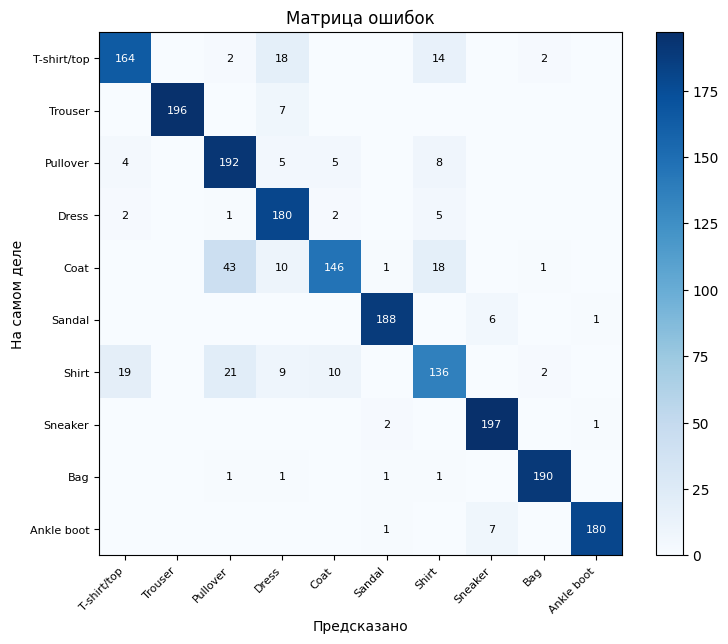

In [ ]:
# Матрица ошибок: строка = настоящий класс, столбец = что предсказала сеть
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(8, 6.5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right", fontsize=8)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES, fontsize=8)
plt.xlabel("Предсказано"); plt.ylabel("На самом деле")
plt.title("Матрица ошибок"); plt.tight_layout(); plt.show()

In [ ]:
# Какие классы сеть путает сильнее всего?
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

per_class = cm.diagonal() / cm.sum(axis=1).clip(min=1)
order = np.argsort(per_class)
print("ХУДШИЕ классы (их сеть распознаёт хуже всего):")
for i in order[:3]:
    wrong = np.argsort(-cm[i])[1]        # самый частый неверный ответ
    print(f"  {CLASS_NAMES[i]:<28} accuracy {per_class[i]*100:5.1f}%  | чаще всего путает с '{CLASS_NAMES[wrong]}'")
print("\nЛУЧШИЕ классы:")
for i in order[-3:][::-1]:
    print(f"  {CLASS_NAMES[i]:<28} accuracy {per_class[i]*100:5.1f}%")

              precision    recall  f1-score   support

 T-shirt/top      0.868     0.820     0.843       200
     Trouser      1.000     0.966     0.982       203
    Pullover      0.738     0.897     0.810       214
       Dress      0.783     0.947     0.857       190
        Coat      0.896     0.667     0.764       219
      Sandal      0.974     0.964     0.969       195
       Shirt      0.747     0.690     0.718       197
     Sneaker      0.938     0.985     0.961       200
         Bag      0.974     0.979     0.977       194
  Ankle boot      0.989     0.957     0.973       188

    accuracy                          0.884      2000
   macro avg      0.891     0.887     0.885      2000
weighted avg      0.890     0.884     0.883      2000

ХУДШИЕ классы (их сеть распознаёт хуже всего):
  Coat                         accuracy  66.7%  | чаще всего путает с 'Pullover'
  Shirt                        accuracy  69.0%  | чаще всего путает с 'Pullover'
  T-shirt/top                  a

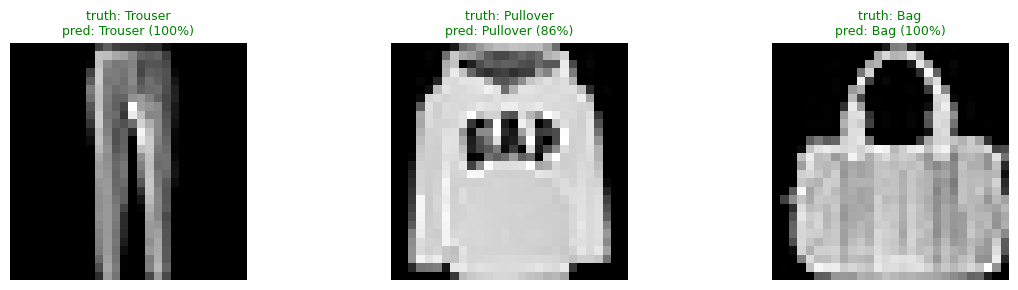

Если уверенность высокая, а ответ неверный — это 'уверенная ошибка':
такую модель нельзя пускать в продакшн без порога доверия (confidence threshold).


In [ ]:
# Уверенность модели: насколько она «сомневается» в ответе
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, i in zip(axes, random.Random(3).sample(range(len(test_ds)), 3)):
    x, y = test_ds[i]
    cls, conf, probs = predict_one(model, x)
    img = x.squeeze(0).numpy() if IN_CHANNELS == 1 else x.numpy().transpose(1, 2, 0)
    if img.ndim == 3: img = img * 0.5 + 0.5
    ax.imshow(img, cmap="gray" if IN_CHANNELS == 1 else None)
    ax.set_title(f"truth: {CLASS_NAMES[y]}\npred: {CLASS_NAMES[cls]} ({conf:.0%})",
                 fontsize=9, color="green" if cls == y else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

print("Если уверенность высокая, а ответ неверный — это 'уверенная ошибка':")
print("такую модель нельзя пускать в продакшн без порога доверия (confidence threshold).")

## Выводы (заполните своими цифрами)

1. До обучения сеть со случайными весами дала accuracy `___ %`, что примерно равно случайному угадыванию `___ %`.
2. После `___` эпох обучения accuracy выросла до `___ %`, loss уменьшился с `___` до `___`.
3. Хуже всего сеть распознаёт класс `___`, путая его с `___`, потому что `___`.
4. Параметры, которые я менял(а) и что они дали: `___`.


## Домашнее задание

**Задание 1 (обязательное). Свой классификатор.**
Обучите модель на **другом** датасете и получите accuracy не ниже 80%. Варианты:
* **А.** Поменять в настройках `DATASET = "cifar"` (цветные фото) и `IN_CHANNELS` подхватится сам. Подберите `CHANNELS`/`EPOCHS`, чтобы вышло ≥ 65%.
* **Б.** Свой датасет: сфотографировать 3 класса по 30–50 фото (кружка / бутылка / ноутбук), разложить по папкам `data/мой_класс/...` и обучить `ImageFolder`.

**Задание 2 (обязательное). Эксперимент с гиперпараметрами.**
Проведите **минимум 4** запуска, меняя по одному параметру, и заполните таблицу:

| № | Что изменил | TRAIN_SIZE | CHANNELS | EPOCHS | LR | Test accuracy | Время, с |
|---|---|---|---|---|---|---|---|
| 1 | базовый запуск | 10000 | 32 | 8 | 1e-3 | | |
| 2 | меньше данных | 2000 | 32 | 8 | 1e-3 | | |
| 3 | шире сеть | 10000 | 64 | 8 | 1e-3 | | |
| 4 | больше эпох | 10000 | 32 | 16 | 1e-3 | | |

Сделайте вывод: **что сильнее всего влияет на качество** в вашем эксперименте.

**Задание 3 (повышенной сложности).** Добавьте в сеть третий свёрточный слой или аугментации (`transforms.RandomHorizontalFlip()`, `transforms.RandomRotation(10)`) и покажите, как изменилась accuracy на тесте.

**Форма отчёта:** ноутбук с выполненными ячейками + таблица экспериментов + 4 вывода своими словами.